<a href="https://colab.research.google.com/github/artkula/ML-retreat-tekmek-2026/blob/main/1-CNN/CNN_handson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep neural networks for modal decomposition of flow-field data
## Contents
### 1.   Autoencoders

*   Dimension reduction
*   Approximation of the Koopman operator

### 2.   Convolutional neural network (CNN) based autoencoders


*   Convolution operation, down-sampling and up-sampling
*   CNNs for modal decomposition




*Based on the material developed by Hamidreza Eivazi and Ricardo Vinuesa (KTH), adapted by Artem Kulachenko and Marta Alloisio. Extended for the TekMek AI retreat 2026 with labelled convolution kernels and a look at the kernels the network learns.*

The notebook is complete: every cell runs as it is, from top to bottom. On a Colab T4 GPU the three training runs take a few minutes each.

## Dataset

The dataset is obtained from a DNS simulation of 2D viscous flow past two colinear  plates, aligned perpendicular to the freestream velocity. The plates each have unit length, and the gap between them is also unity. The Reynolds number (based on free-stream velocity and the length of one plate) is 100.

The data is stored in a 4D NumPy array with the shape of $(n_t, n_x, n_y, n_v)$ where $n_t$ indicates the number of time snapshots. $n_x$ and $n_y$ are the number of grid points in $x$ and $y$ directions, respectively, and $n_v$ represents the number of variables, which are velocity components $u$ and $v$.

### Flow configuration

Two plates of length $L = 1$, separated by a gap of $L = 1$, stand perpendicular to a uniform free stream $U_\infty$ at $Re = U_\infty L/\nu = 100$. The wake behind the plates is unsteady, and this velocity field is the data we compress below.

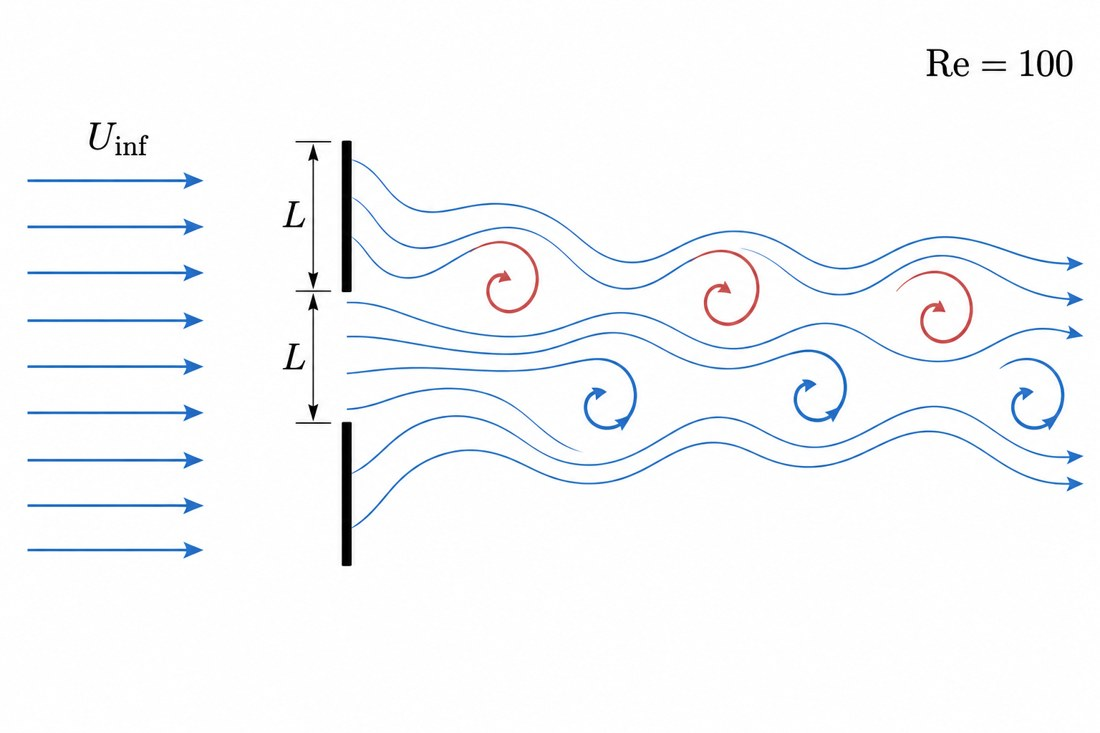

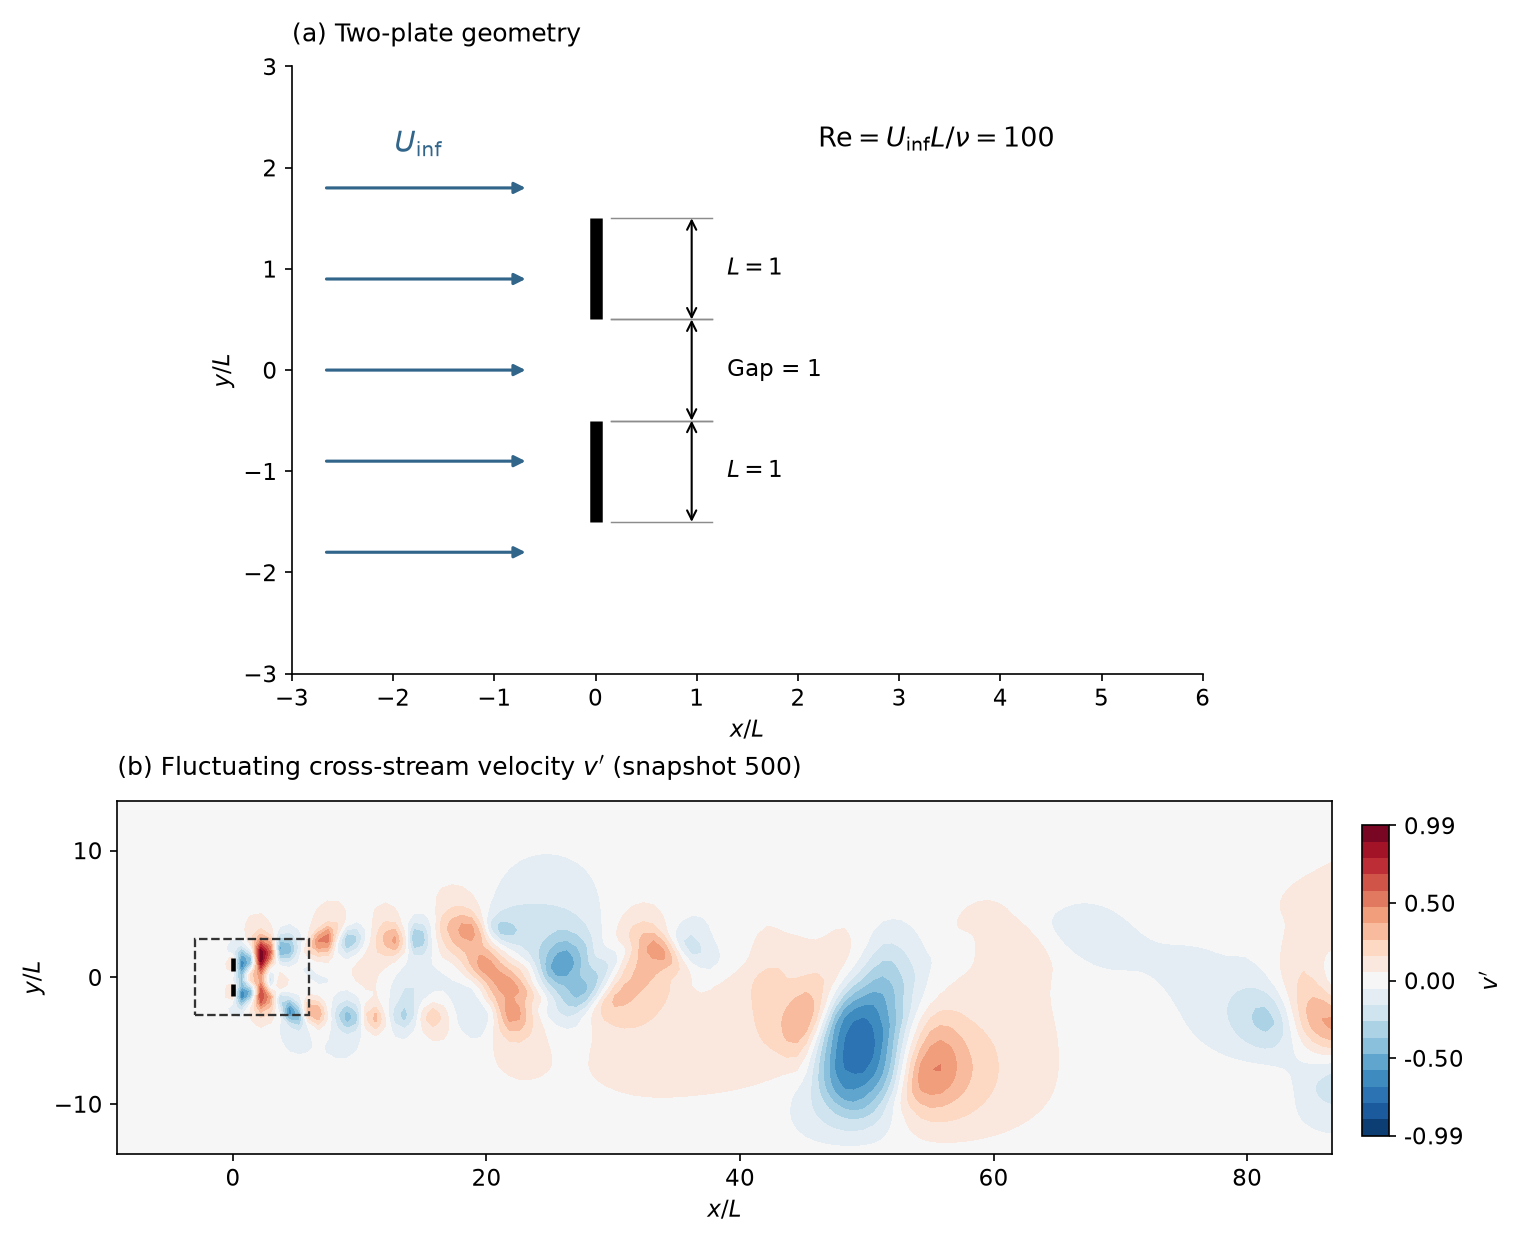

*Top: illustration of the configuration. Bottom: (a) geometry near the plates; (b) fluctuating cross-stream velocity $v'$ from the dataset, with the dashed box marking the region in (a).*


## Import required packages and load the data

In [ ]:
#@title Install missing packages (runs on Colab and on your own computer; installs only what is missing)
import importlib.util, subprocess, sys

REQUIRED = {'numpy': 'numpy', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn', 'tensorflow': 'tensorflow', 'gdown': 'gdown'}  # module to import: package to install

def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:
        return True

missing = [pkg for mod, pkg in REQUIRED.items() if _missing(mod)]
if missing:
    print("Installing:", " ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Done.")
else:
    print("All required packages are installed.")


This cell imports NumPy, Matplotlib, scikit-learn and TensorFlow with Keras, then downloads the flow data into `data.npz` (about 124 MB) with `gdown`. Wait until the progress bar shows “100%” before you run the next cell.

In [ ]:
# import necessary packages
import numpy as np
# library for plotting
from matplotlib import pyplot as plt
# library for cross-validation, needed for splitting the dataset
from sklearn.model_selection import train_test_split

import tensorflow as tf
# import keras routines from tensorflow
from tensorflow.keras import layers, models, activations, optimizers, callbacks, metrics
# this one is needed for the download
import gdown

url = 'https://drive.google.com/uc?id=1b_pJl1XBfzlb93IcB4USht1voHBW6-IE'
output = 'data.npz'
# download the data and store in a designated file
gdown.download(url, output, quiet=False)

We load the data into NumPy arrays. The data is stored on a uniformly-spaced 2D grid (the original simulation has higher resolution). The array `v` holds both velocity components: channel 0 is $u$, the streamwise velocity along $x$ (the flow direction), and channel 1 is $v$, the cross-stream velocity along $y$.

In [ ]:
# load the dictionary from the file and
# transfer NumPy array to x and y and velocity data
data = np.load('data.npz')
xx = data['x']
yy = data['y']
v = data['UV']

We remove the mean flow from the data as we are only interested in the fluctuations around it.

In [ ]:
# report the shape (# of time snapshots, # of point in x, in y, # of variable, namely u and v velocities)
print(v.shape)
# remove the steady mean flow; "axis 0" means row-wise evaluation of the mean
v_mean = v.mean(axis = 0)
v -= v_mean # v = v - v_mean

Now, let us plot the data. Observe vortexes - challenging for POD, requiring many modes to capture it with reasonable accuracy.

In [ ]:
fig, ax = plt.subplots(1, 2, sharex = True, sharey = True, figsize = (16, 4))
plt.set_cmap('RdBu_r')

ax[0].contourf(xx, yy, v[0, :, :, 0], levels = 20) # 20 fringes
ax[1].contourf(xx, yy, v[0, :, :, 1], levels = 20)

ax[0].set_xlabel('x')
ax[1].set_xlabel('x')

ax[0].set_ylabel('y')

ax[0].set_title('u')
ax[1].set_title('v')

ax[0].set_aspect('equal')
ax[1].set_aspect('equal')

# Autoencoders

An autoencoder is a deep neural network (DNN) with an architecture suitable for unsupervised feature extraction. The network consists of two parts: an encoder that maps the input data to a low-dimensional latent space $\boldsymbol{x} \mapsto \boldsymbol{z}$, and a decoder that projects the latent vector $\boldsymbol{z}$ back to the reference space $\boldsymbol{z} \mapsto \boldsymbol{\tilde{x}}$. We refer to the encoder and decoder parts as $\phi$ and $\psi$, respectively. Through the model training, the autoencoder learns to extract the most important features in the data that are required for reconstruction by optimizing the model parameters $\boldsymbol{w}$ to minimize the reconstruction loss $\mathcal{L}_\mathrm{rec}$:

$$\mathcal{F} = \psi \circ \phi,$$

$$\boldsymbol{\tilde{x}} = \mathcal{F}(\boldsymbol{x}; \boldsymbol{w}),$$

$$\mathcal{L}_\mathrm{rec} = \epsilon(\boldsymbol{x}, \boldsymbol{\tilde{x}}),$$

where $\boldsymbol{x}$ denotes the input data; $\boldsymbol{\tilde{x}}$ is the reconstruction of the input data and $\epsilon$ represents the loss function. The autoencoder architecture is attractive for modal decomposition as it provides a framework that can incorporate non-linearity in the mappings through the use of non-linear activation functions.

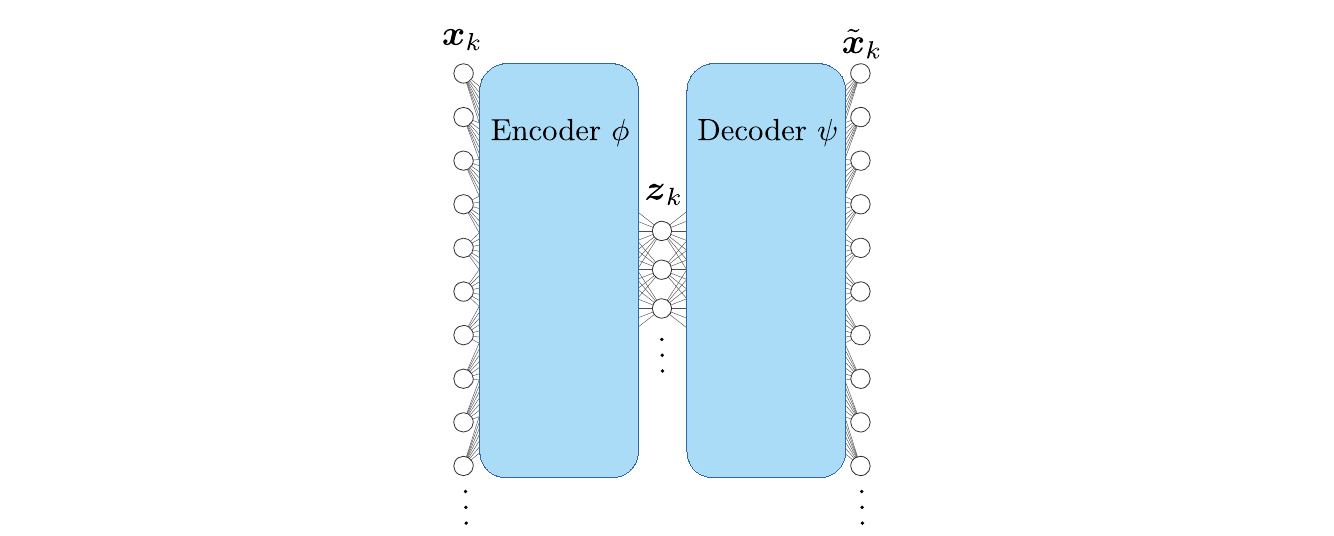

## Dimension reduction

In the following, we implement a simple autoencoder and use it for non-linear dimension reduction. Let's consider $80\%$ of the data for training and $20\%$ for validation.

In [ ]:
nt, nx, ny, nv = v.shape
# split the data, shuffle it and use the random state
# number 24 (just an arbitrary number). The function is from sklearn library
v_trn, v_val = train_test_split(v, test_size = 0.2, random_state = 24, shuffle = True)

Next we fix the size of the network. The latent vector has `d = 10` numbers, the hidden layer has `n_hl_1 = 512` units with ReLU, and one snapshot has `n_state_variables = nx * ny * nv` = 128 x 64 x 2 = 16384 values. Nothing is printed.

In [ ]:
# use the latent vector of length 10 and ReLU as activation functions
d = 10
act = activations.relu # try .sigmoid or .tanh
# number of inputs
n_state_variables = nx * ny * nv
# number of units in a single layer we will use
n_hl_1 = 512

### Encoder

The encoder flattens one snapshot of shape `(nx, ny, nv)` into 16384 numbers, passes them through one dense layer of 512 units and compresses them to `d = 10` numbers. In the summary, note that almost all of the 8.4 million parameters sit in the first dense layer.

In [ ]:
# configure the dimensions for the input layer (1 time instance)
# layers module comes from TensorFlow's Keras
inp = layers.Input(shape = (nx, ny, nv))
# flatten the data into a 1D vector
x = layers.Flatten()(inp)
# setup the fully connected activation layer
# output = activation(dot(W, input) + b) with function act defined earlier
x = layers.Dense(n_hl_1, activation=act)(x)
# setup the latent vector
code = layers.Dense(d)(x)
# configure the encoder and print the summary
encoder = models.Model(inp, code)
print(encoder.summary())

### Decoder

The decoder mirrors the encoder: it maps the 10 latent numbers to 512 units, then to 16384 values, and `Reshape` turns them back into a field of shape `(nx, ny, nv)`. The last dense layer has no activation, so the output can take negative velocities.

In [ ]:
# the decoder is set up similar to encoder but in the reverse fashion starting from the latent vector
code_d = layers.Input(shape = (d,)) # by (d,)  we provide expected tuple, a built-in data structure in Python
x = layers.Dense(n_hl_1, activation=act)(code_d)
x = layers.Dense(n_state_variables)(x)
# unflatten the data
out = layers.Reshape((nx, ny, nv))(x)

decoder = models.Model(code_d, out)
print(decoder.summary())

Observe the total number of parameters - there is a risk of overfitting.

### Autoencoder

Here the encoder and decoder are joined into one `model` that takes a snapshot and returns its reconstruction. The summary shows the two parts, `encoder` and `decoder`, with about 16.8 million parameters in total.

In [ ]:
# put the encoder and decoder together
out_d = decoder(encoder(inp))

model = models.Model(inp, out_d)
print(model.summary())

## Model training

### Callbacks
We use early stopping and save the best model based on the validation loss to avoid overfitting.

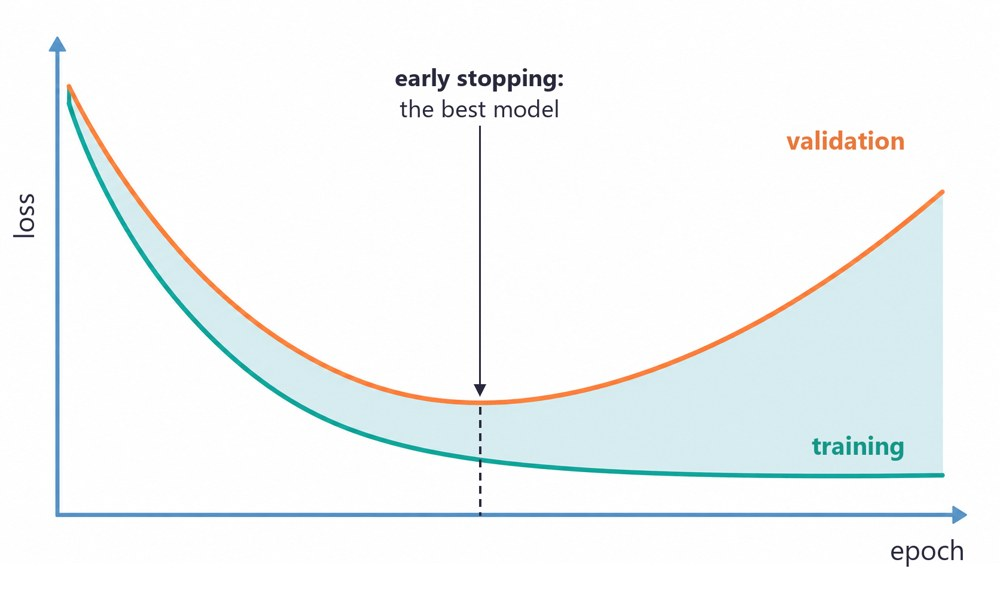

*Training error keeps falling while the validation error turns up: the network starts to memorise. Early stopping keeps the model at the minimum of the validation error.*

In [ ]:
# callback is a set of functions to be applied at specified stages of the training process
# configure the policies of overfitting (if the validation loss is not improving for 20 EPOCH - quit)
Es = callbacks.EarlyStopping(
    monitor='val_loss',  # monitor the validation loss during training
    patience=20          # number of epochs with no improvement to wait before stopping the training
)
# best result will be based
checkpoint_filepath = 'checkpoint_NN.weights.h5'
# initialize the ModelCheckpoint callback from Keras' callbacks module
checkpoint = callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,   # specify the file path where the model weights will be saved
    save_weights_only=True,         # save only the weights of the model, not the entire model
    monitor='val_loss',             # monitor the validation loss during training
    mode='min',                     # the goal is to minimize the monitored metric ('val_loss' in this case)
    save_best_only=True             # save only the best model, i.e., the model with the minimum validation loss
)

# Form list of callbacks to be used during training
callbacks_list = [Es, checkpoint]

### Optimizer, loss function, and model training

We employ Adam with a piecewise constant decay of the learning rate as the optimizer and the mean-squared error as the loss function.

In [ ]:
step = tf.Variable(0, trainable=False)
steps_per_epoch = int(np.ceil(len(v_trn) / 32))  # Keras default batch size is 32
boundaries = [100 * steps_per_epoch, 150 * steps_per_epoch]  # lower the learning rate after epochs 100 and 150
# use varied learning rate with piecewise constant decay
values = [1e-3, 1e-4, 1e-5]
lr = optimizers.schedules.PiecewiseConstantDecay(boundaries, values)
# Adam optimiser
opt = optimizers.Adam(learning_rate = lr)
# mse - mean square error
model.compile(optimizer = opt, loss = 'mse', metrics=['mse'])
# Fitting the model to the training data
hist = model.fit(
    v_trn, v_trn,                     # training data and corresponding labels (labels are same as data for autoencoders)
    epochs=200,                       # number of training epochs
    callbacks=callbacks_list,         # list of callbacks to apply during training
    validation_data=(v_val, v_val),   # validation data and corresponding labels
    verbose=2                         # verbosity level; 2 means one line per epoch
)
# plot how loss evolved
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

### Saving the best model based on the validation loss

The last epoch is usually not the best one, so we reload the weights that `checkpoint` saved at the lowest validation loss. The encoder and decoder are then saved as separate files, `NN_AE_10_encoder.keras` and `NN_AE_10_decoder.keras`, so that each half can be reused later.

In [ ]:
# retrieve best model fit based on the configured callback policies
model.load_weights(checkpoint_filepath)
# make the model name
model_name = f'NN_AE_{d}'
print(model_name)
# save the trained model
encoder.save(model_name + '_encoder.keras')
decoder.save(model_name + '_decoder.keras')

### Flow field reconstruction

Now, we can compare the reconstruction of the flow field for a snapshot from the validation data with the reference data.

In [ ]:
# use the trained model to make predictions on the validation data
v_val_rec = model.predict(v_val)

# create a 2x2 grid of subplots with shared x and y axes, and set the figure size
fig, ax = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 4))

# set the colormap to 'RdBu_r'
plt.set_cmap('RdBu_r')

# find the minimum and maximum values of the last sample in the validation set for u and v
vmin0 = v_val[-1, :, :, 0].min()
vmax0 = v_val[-1, :, :, 0].max()
vmin1 = v_val[-1, :, :, 1].min()
vmax1 = v_val[-1, :, :, 1].max()

# plot the contour maps of the last sample in the validation set for  u and v
ax[0, 0].contourf(xx, yy, v_val[-1, :, :, 0], vmin=vmin0, vmax=vmax0, levels=20)
ax[1, 0].contourf(xx, yy, v_val[-1, :, :, 1], vmin=vmin1, vmax=vmax1, levels=20)

# plot the contour maps of the reconstructed data for u and v
ax[0, 1].contourf(xx, yy, v_val_rec[-1, :, :, 0], vmin=vmin0, vmax=vmax0, levels=20)
ax[1, 1].contourf(xx, yy, v_val_rec[-1, :, :, 1], vmin=vmin1, vmax=vmax1, levels=20)

# set axis labels for the subplots
ax[0, 0].set_ylabel('y')
ax[1, 0].set_ylabel('y')
ax[1, 0].set_xlabel('x')
ax[1, 1].set_xlabel('x')

# set titles for the subplots
ax[0, 0].set_title('$u$ reference')
ax[1, 0].set_title('$v$ reference')
ax[0, 1].set_title('$u$ reconstruction')
ax[1, 1].set_title('$v$ reconstruction')

# ensure that the aspect ratios of the subplots are equal
for axx in ax.flatten():
    axx.set_aspect('equal')

# adjust the layout to ensure that the plots are displayed correctly
fig.tight_layout()


Moreover, we can define the error in the reconstructions as the average relative $\ell_2$-norm of errors for all the snapshots as:

\begin{equation}
\boldsymbol{\epsilon} = \dfrac{1}{n_t}\sum_{i = 1}^{i = n_t}\dfrac{||\boldsymbol{v} - \boldsymbol{\tilde{v}}||}{||\boldsymbol{v}||},
\end{equation}
where $||\cdot||$ indicates $\ell_2$-norm.

In [ ]:
# Define a function to calculate the relative reconstruction error between original and predicted data
def error_rec(v, v_p):
    """
    parameters:
        v: np.ndarray
            Original data array.
        v_p: np.ndarray
            Predicted or reconstructed data array.

    returns:
        err: float
            Mean relative reconstruction error.
    """
    # compute the Frobenius norm of the difference between original and predicted data along specified axes (1 and 2)
    # then normalize it by the Frobenius norm of the original data along the same axes
    err = np.linalg.norm(v - v_p, axis=(1, 2)) / np.linalg.norm(v, axis=(1, 2))

    # take the mean of the computed errors along axis 0 (likely representing different samples)
    err = np.mean(err, axis=0)

    return err

# use the trained model to make predictions on the entire dataset 'v'
v_rec = model.predict(v)

# calculate the relative reconstruction error using the defined function
error = error_rec(v, v_rec)

# print the calculated error
print(error)


## Background: Proper Orthogonal Decomposition (POD)

POD is the linear baseline that the autoencoder will be compared with. It splits the flow into a few fixed spatial patterns (modes) and a time signal for each.

**Snapshots.** Each of the $n_t$ velocity fields $v(x, t_k)$ is flattened into a column. The columns form the snapshot matrix $X$ of size $(n_x n_y \cdot 2) \times n_t$.

**SVD.** $X = U \Sigma V^T$.
- The columns of $U$ are the spatial modes $\phi_i(x)$, orthonormal.
- The singular values $\sigma_1 \ge \sigma_2 \ge \dots$ rank the modes by energy: $\sigma_i^2$ is proportional to the kinetic energy that mode $i$ carries. The mean flow was subtracted at the start (`v -= v_mean`), so the modes describe the fluctuations around the mean.
- Row $i$ of $\Sigma V^T$ is the time coefficient $a_i(t)$ of mode $i$.

**Truncation.** Keeping the first $d$ modes gives

$$v(x, t) \approx \sum_{i=1}^{d} a_i(t)\, \phi_i(x).$$

For a given $d$, no other linear basis reconstructs the snapshots with a smaller squared error.

**The parallel with structural dynamics.**

| Structural dynamics | POD of a flow |
|---|---|
| Eigenmodes $\phi_i$ from $(K - \omega_i^2 M)\phi_i = 0$ | POD modes $\phi_i$ from the SVD of the snapshots |
| Modal superposition $u(x,t) = \sum q_i(t)\, \phi_i(x)$ | $v(x,t) = \sum a_i(t)\, \phi_i(x)$ |
| Keep the lowest few modes (modal truncation) | Keep the most energetic few modes |
| Modes come from the model ($K$, $M$) | Modes come from data (measured or simulated fields) |

POD modes are the eigenvectors of the spatial correlation matrix $X X^T$, so the idea is the same: an eigenvalue problem gives a basis, and a few basis vectors describe the motion. The difference is the ranking: eigenmodes are ranked by frequency, POD modes by energy.

**Why the autoencoder.** POD is linear: the field is a weighted sum of fixed modes. The vortices in the wake travel downstream, and a travelling pattern needs many fixed modes. The CNN autoencoder below also compresses each field to $d$ numbers, but its decoder is nonlinear. With the same $d$ it can reconstruct the field better than POD.

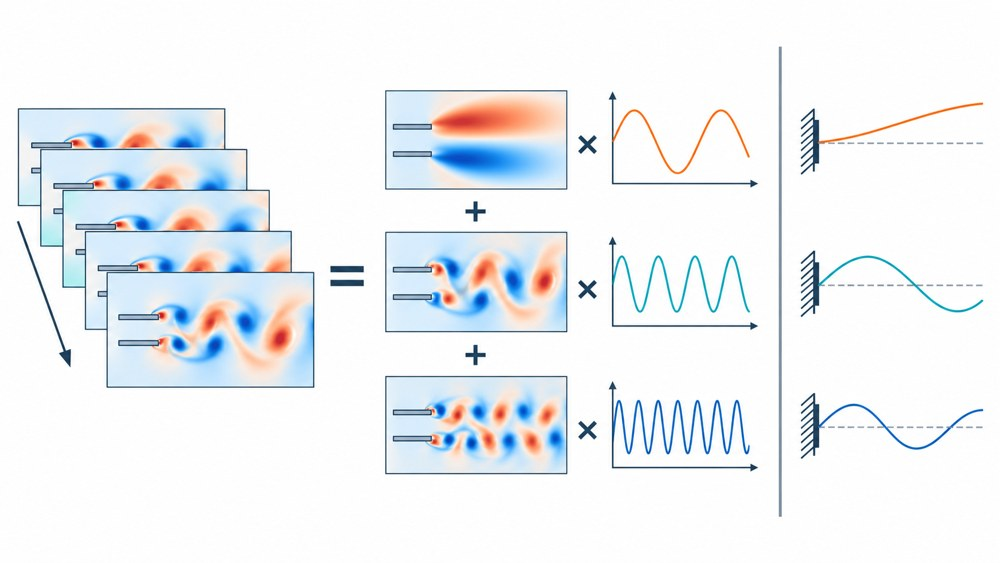

*Left: snapshots of the wake. Middle: POD writes them as a sum of spatial modes, each multiplied by its own time coefficient. Right: the same idea in structural dynamics, the first bending modes of a cantilever.*

###Flow field reconstruction using POD

This cell computes the POD of the same snapshots with an SVD and keeps the first `d = 10` modes, the same size as the latent vector. `pod_err` uses the same `error_rec`, so compare its two numbers (for $u$ and $v$) directly with the autoencoder error above. The reshaped `U` is used at the end of the notebook to plot the POD modes.

In [ ]:
# compute the Singular Value Decomposition (SVD) of the reshaped data 'v' with d modes
# 'U', 's', and 'vh' are the left singular vectors, singular values, and right singular vectors, respectively
# 'full_matrices=False' specifies reduced SVD, which is computationally less intensive and often sufficient for many applications.
U, s, vh = np.linalg.svd(v.reshape((nt, -1)).T, full_matrices=False)

# reconstruct the data using the first 'd' modes obtained from SVD
# here '@' represents matrix multiplication, and np.diag(s[:d]) creates a diagonal matrix from the first 'd' singular values
v_pod = U[:, :d] @ np.diag(s[:d]) @ vh[:d]

# reshape the reconstructed data back to its original shape
v_pod = v_pod.T.reshape((-1, nx, ny, 2))

# calculate the relative reconstruction error between the original and POD-reconstructed data using the custom error function
pod_err = error_rec(v, v_pod)
print(pod_err)

# reshape the left singular vectors 'U' back to its original shape for further use
U = U.T.reshape((-1, nx, ny, 2))


$~~$

# Approximation of the Koopman operator

The Koopman operator theory is central to all that follows in this section, therefore we provide a brief overview of the mathematical aspects. we focus on an autonomous discrete-time dynamical system:
\begin{equation}
    \boldsymbol{x}_{t+1} = \mathbf{F}(\boldsymbol{x}_{t}),
\end{equation}
where $\mathbf{F}$ is the evolution operator. The Koopman operator $\boldsymbol{K}$ is defined as an infinite-dimensional linear operator that acts on functions of state space $g$. The action of the Koopman operator is:

$$\boldsymbol{K} g = g \circ\mathbf{F},$$

where $\circ$ indicates the composition of $g$ with $\mathbf{F}$.
In fact, the Koopman operator defines a new infinite-dimensional linear dynamical system that governs the evolution of the observables $g_{t} = g(\mathbf{x}_t)$ in discrete time.
The Koopman operator can be approximated through the DMD algorithm.

$$\boldsymbol{x}_{k+1} = \boldsymbol{A} \boldsymbol{x}_{k}.$$


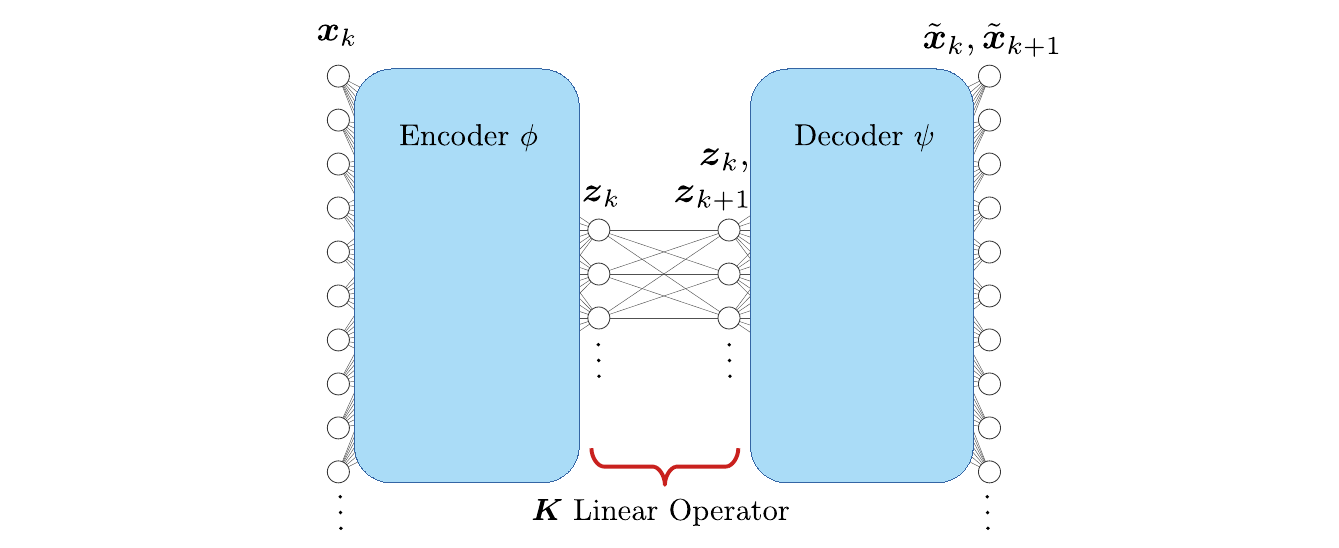

Let's prepare training and validation datasets.

Each input in `X` is the snapshot at time step $k$, and its target in `y` is the snapshot at step $k+1$: `v[:-1]` and `v[1:]` are the same series shifted by one step. The pairs are split into 80% for training and 20% for validation with the same `random_state = 24` as before.

In [ ]:
# the trick: data is presented as two sets with a 1-step time shift between the
# 'v[:-1]' contains all but the last element, serving as the input (X), and 'v[1:]' contains all but the first element, serving as the output (y).
# the data is then split into training and validation sets using a 20% test size.
X_trn, X_val, y_trn, y_val = train_test_split(v[:-1], v[1:], test_size=0.2, random_state=24, shuffle=True)


This cell builds the model in four parts: an encoder, a model with one linear layer as the Koopman operator, a decoder, and a multi-output network that uses all three. The linear operator `Loperator` is one `Dense(d, use_bias=False)` layer, that is a 10 x 10 matrix with 100 weights. The model `AELO` returns two fields: the reconstruction `out` and the prediction of the next snapshot `out_next`.

In [ ]:
# Define the encoder part of the autoencoder
inp_en = layers.Input(shape=(nx, ny, nv))  # Input layer for the encoder with shape (nx, ny, nv)
x = layers.Flatten()(inp_en)  # Flatten the input for subsequent dense layers
x = layers.Dense(n_hl_1, activation=act)(x)  # Dense layer with 'n_hl_1' units and activation function 'act'
code = layers.Dense(d)(x)  # Encoding layer compresses the input into 'd' dimensions

encoder = models.Model(inp_en, code, name='encoder')  # Assemble the encoder model
print(encoder.summary())  # Output the summary of the encoder architecture


# Define the linear operator part
inp_Loperator = layers.Input(shape=(d,))  # Input layer for the linear operator with shape (d,)
out_Loperator = layers.Dense(d, use_bias=False)(inp_Loperator)  # Dense layer with 'd' units and no bias

Loperator = models.Model(inp_Loperator, out_Loperator, name='linear_operator')  # Assemble the linear operator model
print(Loperator.summary())  # Output the summary of the linear operator architecture


# define the decoder part of the autoencoder
inp_de = layers.Input(shape=(d,))  # input layer for the decoder with shape (d,)
x = layers.Dense(n_hl_1, activation=act)(inp_de)  # dense layer with 'n_hl_1' units and activation function 'act'
x = layers.Dense(n_state_variables)(x)  # dense layer that expands to 'n_state_variables'
out_de = layers.Reshape((nx, ny, nv))(x)  # reshape the output to match the original data shape (nx, ny, nv)

decoder = models.Model(inp_de, out_de, name='decoder')  # Assemble the decoder model
print(decoder.summary())  # Output the summary of the decoder architecture


# assemble the complete model
out = decoder(encoder(inp_en))  # output from the autoencoder
out_next = decoder(Loperator(encoder(inp_en)))  # output after applying the linear operator to the encoding

model = models.Model(inp_en, [out, out_next], name='AELO')  # assemble the entire model "AELO" (AutoEncoder with Linear Operator).
print(model.summary())  # output the summary of the architecture


Training uses the same callbacks and learning-rate schedule as before. The model has two outputs, so the target is `[X_trn, y_trn]`: the current snapshot for the reconstruction and the next snapshot for the prediction. The printed `loss` is the sum of the two mean-squared errors.

In [ ]:
# initialize early stopping callback to monitor validation loss and stop training if it doesn't improve for 20 epochs
Es = callbacks.EarlyStopping(monitor='val_loss', patience=20)

# initialize the ModelCheckpoint callback to save the model with the lowest validation loss
checkpoint_filepath = 'checkpoint_NN.weights.h5'
checkpoint = callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,  # filepath to save the model
    save_weights_only=True,        # save only weights, not the entire model
    monitor='val_loss',            # monitor validation loss
    mode='min',                    # minimize validation loss
    save_best_only=True            # save only the best model
)

# create a list of callbacks to be used during training
callbacks_list = [Es, checkpoint]

# initialize learning rate schedule
step = tf.Variable(0, trainable=False)  # training step variable (not trainable)
steps_per_epoch = int(np.ceil(len(X_trn) / 32))  # Keras default batch size is 32
boundaries = [100 * steps_per_epoch, 150 * steps_per_epoch]  # lower the learning rate after epochs 100 and 150                 # learning rate change boundaries
values = [1e-3, 1e-4, 1e-5]             # learning rates for different intervals
lr = optimizers.schedules.PiecewiseConstantDecay(boundaries, values)  # Piecewise constant decay schedule

# initialize optimizer
opt = optimizers.Adam(learning_rate = lr)

# compile the model with Mean Squared Error (MSE) loss
model.compile(optimizer=opt, loss='mse')

# train the model
# the model expects two outputs, so we provide [X_trn, y_trn] as target data
hist = model.fit(X_trn, [X_trn, y_trn], epochs=200, callbacks=callbacks_list, validation_data=(X_val, [X_val, y_val]), verbose=2)


Evaluate the model:

We reload the best weights and evaluate both outputs on the validation pairs. `error_rec_val` measures how well the snapshot itself is reconstructed, and `error_koop` how well the next snapshot is predicted. Expect the propagation error to be larger, because it adds the error of the linear step.

In [ ]:
model.load_weights(checkpoint_filepath)  # use the best weights from training
# make predictions on the validation set
predictions = model.predict(X_val)
# reconstructions
x_rec = predictions[0]

# reconstruction error
error_rec_val = error_rec(X_val, x_rec)
print('Reconstruction error:', error_rec_val)

# Propagated states
x_koop = predictions[1]

# Short-term propagation error
error_koop = error_rec(y_val, x_koop)  # predicted next state against the true next state
print('Koopman propagation Error:', error_koop)


# Convolutional neural network (CNN) based autoencoders

Through a two-dimensional convolution layer and using a so-called filter with size $H\times H \times K$, the data is processed as:
\begin{equation}
    \boldsymbol{x}^{(l)}_{ijm} = \varphi \left ( \sum_{k = 1}^{K} \sum_{p = 1}^{H} \sum_{q = 1}^{H} \boldsymbol{x}^{(l-1)}_{i+p, j+q, k}\boldsymbol{w}^{(l)}_{pqkm} + \boldsymbol{b}^{(l)}_{ijm} \right ),
\end{equation}
where $\boldsymbol{x}^{(l-1)}$ and $\boldsymbol{x}^{(l)}$ represent the input and output variables, respectively. Note that $\boldsymbol{w}^{(l)}$ and $\boldsymbol{b}^{(l)}$ denote the weights and the biases of layer $l$, and $\varphi$ denotes the activation function. Furthermore, $K$ is the number of the so-called kernels, which are the two-dimensional slices of the filter.

It is common to use convolution layers together with the pooling and upsampling layers. Through a pooling operation, the data are compressed by a factor of $(1/P)^2$ so that a region with size of $P \times P$ is represented by e.g. its maximum value; this is the so-called max-pooling operation.

The upsampling operation is used to expand the data dimension by e.g. nearest-neighbor or bilinear interpolation.

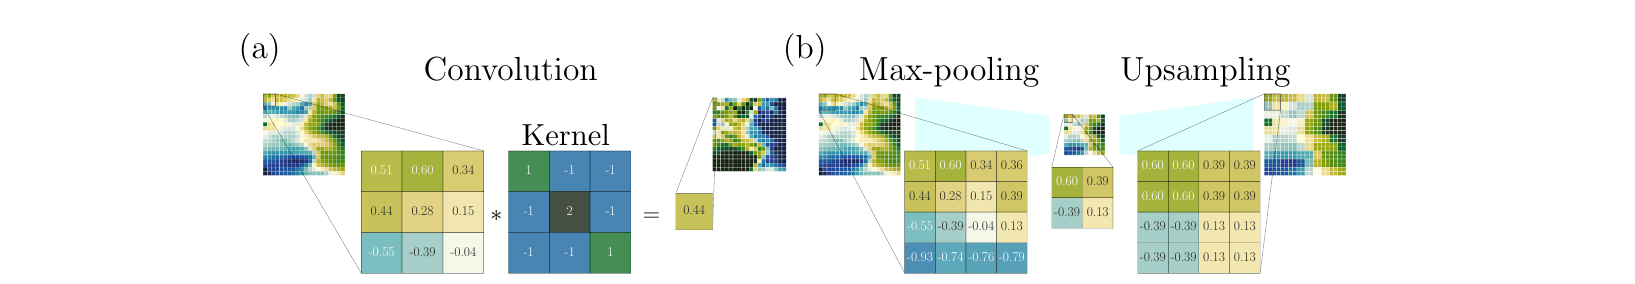

## Convolution: what a kernel does

A convolution slides a small kernel over the field and replaces every point by a weighted sum of its neighbours. We first apply kernels whose weights we choose ourselves, so that we know what to expect. Then we look at a kernel with random weights, which is how every kernel in a CNN starts before training. At the end of the notebook we look at the kernels the trained network has learned.

The kernels are printed in the corner of each plot as they lie on the plot: $x$ to the right and $y$ upwards.

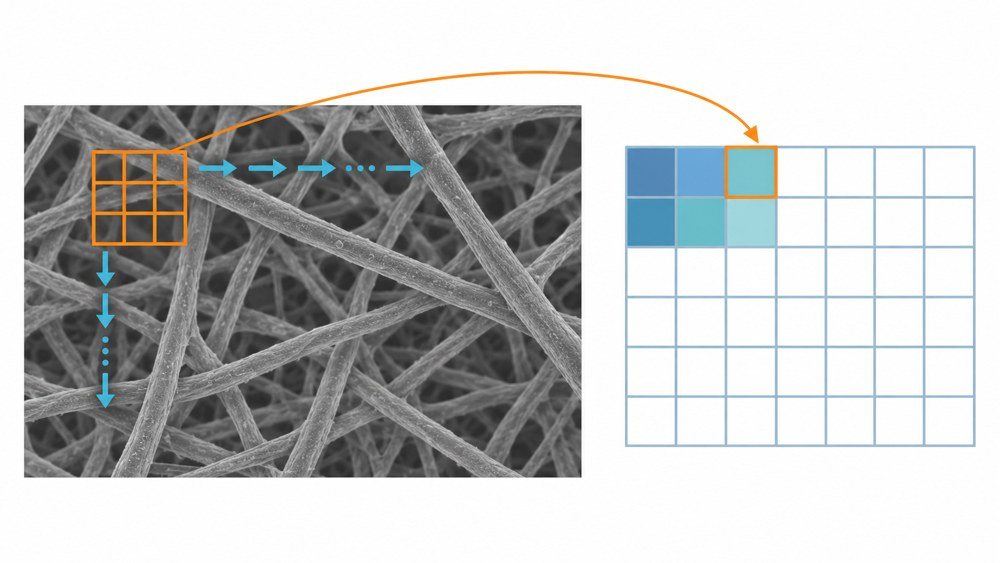

*A 3 x 3 kernel slides over the image; each position gives one value of the output feature map.*

This cell takes the last snapshot of $u$ as a test image `xin` of shape (1, 128, 64, 1) and defines three helpers for the rest of this section: `convolve` applies a kernel, `kernel_text` prints a kernel, and `show` plots fields on the physical grid. Only the shape is printed.

In [ ]:
# last snapshot, u component, shape (1, nx, ny, 1): one sample, one channel
xin = v[-1:, :, :, 0:1].astype(np.float32)
print(xin.shape)


def convolve(field, kernel):
    """Apply one 2D kernel to a field of shape (1, nx, ny, 1), zero padding at the edges."""
    k = np.asarray(kernel, dtype=np.float32)[:, :, None, None]
    return tf.nn.conv2d(field, k, strides=1, padding='SAME').numpy()


def kernel_text(kernel):
    """Kernel as text, oriented as on the plot (x to the right, y upwards)."""
    k = np.flipud(np.asarray(kernel, dtype=float).T)
    return '\n'.join(' '.join(f'{w:5.2f}' for w in row) for row in k)


def show(fields, titles, kernels=None, cmap='RdBu_r'):
    """One field per row on the physical grid, the kernel printed to the right.
    Colours are capped at the 99.5th percentile so that the peaks at the plates do not hide the wake."""
    n = len(fields)
    fig, ax = plt.subplots(n, 1, figsize=(12, 2.6 * n), squeeze=False)
    ax = ax[:, 0]
    for i, (f, t) in enumerate(zip(fields, titles)):
        f = np.squeeze(f)
        step = xx.shape[0] // f.shape[0]
        lim = np.percentile(np.abs(f), 99.5)
        lo = 0 if f.min() >= 0 else -lim
        c = ax[i].contourf(xx[::step, ::step], yy[::step, ::step], np.clip(f, lo, lim),
                           levels=np.linspace(lo, lim, 21), cmap=cmap)
        fig.colorbar(c, ax=ax[i], fraction=0.02, pad=0.01, format='%.2f', ticks=np.linspace(lo, lim, 5))
        ax[i].set_title(t, loc='left')
        ax[i].set_aspect('equal')
        ax[i].set_ylabel('y')
        if kernels is not None and kernels[i] is not None:
            ax[i].text(1.13, 0.5, kernel_text(kernels[i]), transform=ax[i].transAxes, va='center',
                       family='monospace', fontsize=10, bbox=dict(facecolor='white', edgecolor='grey'))
    ax[-1].set_xlabel('x')
    fig.tight_layout()
    plt.show()

### Kernels we design ourselves

The first array index of the field runs along $x$ and the second along $y$, so a kernel that differences along the first index is a derivative in $x$. The Sobel kernel combines a central difference in one direction with a light smoothing in the other.

In [ ]:
known = {
    'identity':          np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    'box blur (average)': np.ones((3, 3)) / 9,
    'Sobel, d/dx':        np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    'Sobel, d/dy':        np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
}
outputs = {name: convolve(xin, k) for name, k in known.items()}

show([xin] + list(outputs.values()),
     ['input $u$'] + list(outputs.keys()),
     [None] + list(known.values()))

Check that the labels are right: the Sobel outputs should match the finite-difference derivatives of $u$ (up to a constant factor, since the kernel sums 8 neighbour differences and does not divide by the grid spacing).

In [ ]:
u = xin[0, :, :, 0]
dudx, dudy = np.gradient(u)            # derivatives along the first (x) and second (y) index
inner = (slice(2, -2), slice(2, -2))   # skip the padded edges
for name, ref in [('Sobel, d/dx', dudx), ('Sobel, d/dy', dudy)]:
    out = outputs[name][0, :, :, 0]
    r = np.corrcoef(out[inner].ravel(), ref[inner].ravel())[0, 1]
    print(f'{name}: correlation with np.gradient = {r:.3f}')

The magnitude of the gradient, $\sqrt{(\partial u/\partial x)^2 + (\partial u/\partial y)^2}$, is largest in the shear layers behind the plates and at the edges of the vortices. This is edge detection, the classical use of the Sobel kernel in image processing.

In [ ]:
grad_mag = np.sqrt(outputs['Sobel, d/dx']**2 + outputs['Sobel, d/dy']**2)
show([xin, grad_mag], ['input $u$', 'gradient magnitude (Sobel)'], cmap='magma')

### A kernel with random weights

In a CNN nobody chooses the kernels. Each `Conv2D` layer starts with random weights (Glorot uniform by default) and training adjusts them to reduce the loss. Here is one such kernel before any training. Its output is a mix of smoothing and differencing with no particular purpose. Change the seed and the result changes.

In [ ]:
tf.keras.utils.set_random_seed(0)      # change the seed to get another random kernel
conv_random = layers.Conv2D(1, (3, 3), padding='same', use_bias=False)
y_random = conv_random(xin).numpy()
w_random = conv_random.get_weights()[0][:, :, 0, 0]

show([xin, y_random], ['input $u$', 'random kernel, untrained'], [None, w_random])

## Max-pooling

Max-pooling keeps the largest value in each $2 \times 2$ block, so the field becomes half as large in each direction.

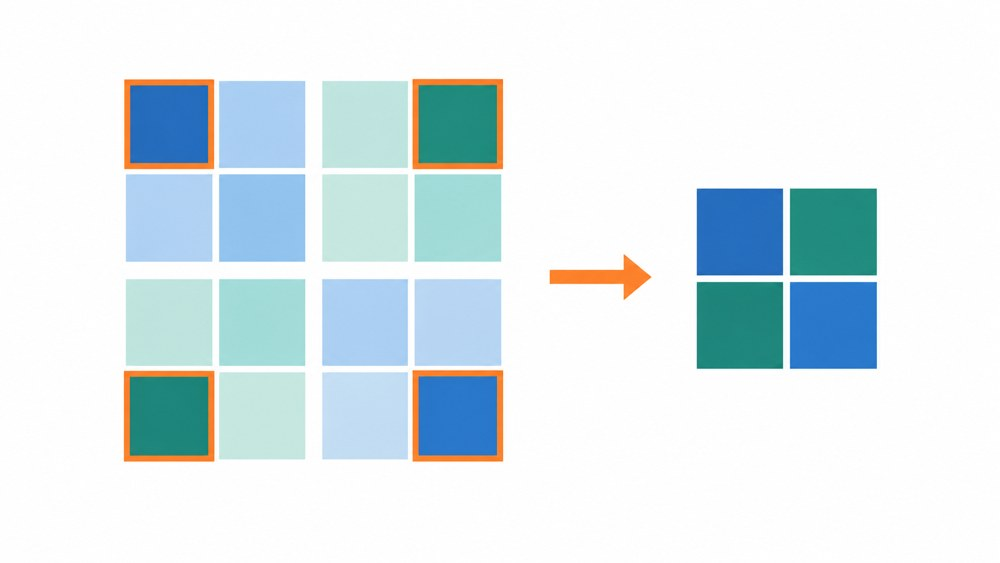

*Max-pooling keeps the strongest value of each 2 x 2 block.*

In [ ]:
max_pool_2d = layers.MaxPooling2D(pool_size=2, padding='same')
ymp = max_pool_2d(xin).numpy()
print(xin.shape, '->', ymp.shape)

show([xin, ymp], [f'input $u$ {xin.shape[1]}x{xin.shape[2]}', f'max-pooled {ymp.shape[1]}x{ymp.shape[2]}'])

## Up-sampling

Up-sampling repeats each value in a $2 \times 2$ block. It restores the size, not the detail that pooling removed.

In [ ]:
upsample_2d = layers.UpSampling2D(size=2)
yup = upsample_2d(ymp).numpy()
print(ymp.shape, '->', yup.shape)

show([xin, ymp, yup], ['input $u$', 'max-pooled', 'pooled, then up-sampled'])

## CNN-based autoencoders

An autoencoder is a deep neural network (DNN) with an architecture specialized for unsupervised feature extraction. The network consists of two parts: an encoder that maps the input data to a low-dimensional latent space $\mathcal{E}:\boldsymbol{v} \mapsto \boldsymbol{r}$ and a decoder that projects the latent vector $\boldsymbol{r}$ back to the reference space $\mathcal{D}:\boldsymbol{r} \mapsto \boldsymbol{\tilde{v}}$ where $\mathcal{E}$ and $\mathcal{D}$ indicate encoder and decoder parts, respectively. Through the model training, the autoencoder learns to extract the most important features in the data that are required for reconstruction by optimizing the model parameters $\boldsymbol{w}$ to minimize the reconstruction loss $\mathcal{L}_\mathrm{rec.}$.

The inputs and outputs of the autoencoder are the same. For this example, we use a filter size of $(3 \times 3)$ and a stride equal to one for convolution layers. At each convolution step we double the number of filters to extract more information from the flow field data while at each downsampling step, through the max pooling operation, we reduce the dimension. After four steps of convolution and max pooling, the extracted features are flattened and fed to fully-connected layers to reduce the dimension to the latent vector $\boldsymbol{r}$ with the size of $d = 10$. The latent vector $\boldsymbol{r}$ is mapped back to the reference space through consecutive upsampling and convolution operations. We use ReLU as the nonlinear activation function in the hidden layers.

The schematic of the network is as follows:



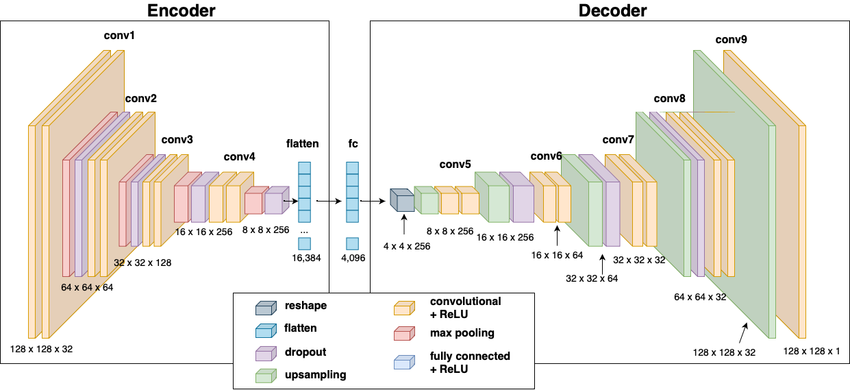

### Encoder

The CNN encoder applies four `Conv2D` layers with 32, 64, 128 and 256 kernels of size 3 x 3, each followed by 2 x 2 max-pooling. The field shrinks from 128 x 64 to 8 x 4, then two dense layers reduce it to `d = 10` numbers. Compare the parameter count in the summary (about 1.4 million) with the 8.4 million of the dense encoder.

In [ ]:
# define hyperparameters
d = 10  # size of the reduced vector in the latent layer
act = activations.relu  # activation function used in the convolution layers
fs = (3, 3)  # filter size for the convolutional kernels
ffs = (2, 2)  # filter size for max pooling
st = (1, 1)  # strides for the convolution operation

# initialize the input layer with the shape of the data (nx, ny, nv)
inp = layers.Input(shape=(nx, ny, nv))

# convolutional Layer with 32 kernels. padding is 'same' and activation function is ReLU.
x = layers.Conv2D(32, fs, activation=act, strides=st, padding='same')(inp)

# max Pooling Layer to reduce dimensions
x = layers.MaxPooling2D(ffs, padding='same')(x)

# second Convolutional Layer with 64 kernels
x = layers.Conv2D(64, fs, activation=act, strides=st, padding='same')(x)

# second Max Pooling Layer
x = layers.MaxPooling2D(ffs, padding='same')(x)

# third Convolutional Layer with 128 kernels
x = layers.Conv2D(128, fs, activation=act, strides=st, padding='same')(x)

# third Max Pooling Layer
x = layers.MaxPooling2D(ffs, padding='same')(x)

# fourth Convolutional Layer with 256 kernels
x = layers.Conv2D(256, fs, activation=act, strides=st, padding='same')(x)

# fourth Max Pooling Layer
x = layers.MaxPooling2D(ffs, padding='same')(x)

# flatten the output of the last Max Pooling Layer
x = layers.Flatten()(x)

# fully connected layer with 128 units and ReLU activation
x = layers.Dense(128, activation=act)(x)

# latent layer with 'd' dimensions
code = layers.Dense(d)(x)

# define the encoder model
encoder = models.Model(inp, code)

# print the summary of the encoder model to see the architecture and parameters
print(encoder.summary())



### Decoder

The decoder runs the same path backwards: two dense layers expand the 10 numbers to 8192 = 8 x 4 x 256 values, and four up-sampling and convolution steps bring the field back to 128 x 64. The last `Conv2D` has `nv = 2` kernels and no activation, so it returns $u$ and $v$ with their signs.

In [ ]:
# with the decoder, you go into the opposite direction
code_d = layers.Input(shape = (d,))
x = layers.Dense(128, activation=act)(code_d)
x = layers.Dense(8192, activation = act)(x)
x = layers.Reshape((8, 4, 256))(x)
x = layers.UpSampling2D(ffs)(x)
x = layers.Conv2D(256, fs, activation = act, strides = st, padding='same')(x)
x = layers.UpSampling2D(ffs)(x)
x = layers.Conv2D(128, fs, activation = act, strides = st, padding='same')(x)
x = layers.UpSampling2D(ffs)(x)
x = layers.Conv2D(64, fs, activation = act, strides = st, padding='same')(x)
x = layers.UpSampling2D(ffs)(x)
x = layers.Conv2D(32, fs, activation = act, strides = st, padding='same')(x)
out = layers.Conv2D(nv, fs, strides = st, padding='same')(x)

decoder = models.Model(code_d, out)
print(decoder.summary())

### Autoencoder

The encoder and decoder are joined into one CNN autoencoder. It has about 3.5 million parameters, against 16.8 million for the dense autoencoder with the same latent size `d = 10`.

In [ ]:
out_d = decoder(encoder(inp))

model = models.Model(inp, out_d)
print(model.summary())

As for the dense autoencoder, we use early stopping and save the best model based on the validation loss to avoid overfitting. Training stops if `val_loss` has not improved for 20 epochs.

In [ ]:

Es = callbacks.EarlyStopping(monitor='val_loss', patience = 20)

checkpoint_filepath = 'checkpoint_NN.weights.h5'
checkpoint = callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

callbacks_list = [Es, checkpoint]

We employ Adam with a piecewise constant decay of the learning rate as the optimizer and the mean-squared error as the loss function, as before. Training runs for at most 200 epochs and takes longer than for the dense model. Watch `val_loss` in the log and compare it with the dense autoencoder.

In [ ]:
step = tf.Variable(0, trainable=False)
steps_per_epoch = int(np.ceil(len(v_trn) / 32))  # Keras default batch size is 32
boundaries = [100 * steps_per_epoch, 150 * steps_per_epoch]  # lower the learning rate after epochs 100 and 150
values = [1e-3, 1e-4, 1e-5]
lr = optimizers.schedules.PiecewiseConstantDecay(boundaries, values)

opt = optimizers.Adam(learning_rate = lr)
model.compile(optimizer = opt, loss = 'mse')
hist = model.fit(v_trn, v_trn, epochs = 200, callbacks = callbacks_list, validation_data = (v_val, v_val), verbose = 2)

We reload the weights with the lowest validation loss and save the two halves as `CNN_AE_10_encoder.keras` and `CNN_AE_10_decoder.keras`. The `encoder` and `decoder` in memory now hold these weights and are used again in the last sections.

In [ ]:
model.load_weights(checkpoint_filepath)
model_name = f'CNN_AE_{d}'

encoder.save(model_name + '_encoder.keras')
decoder.save(model_name + '_decoder.keras')

Now, we can compare the reconstruction of the flow field for a snapshot from the validation data with the reference data. It is the same snapshot with the same colour limits as for the dense autoencoder, so compare the two figures, in particular the vortices in the wake.

In [ ]:
v_val_rec = model.predict(v_val)

fig, ax = plt.subplots(2, 2, sharex = True, sharey = True, figsize = (10, 4))

plt.set_cmap('RdBu_r')

vmin0 = v_val[-1, :, :, 0].min()
vmax0 = v_val[-1, :, :, 0].max()

vmin1 = v_val[-1, :, :, 1].min()
vmax1 = v_val[-1, :, :, 1].max()

ax[0, 0].contourf(xx, yy, v_val[-1, :, :, 0], vmin = vmin0, vmax = vmax0, levels = 20)
ax[1, 0].contourf(xx, yy, v_val[-1, :, :, 1], vmin = vmin1, vmax = vmax1, levels = 20)

ax[0, 1].contourf(xx, yy, v_val_rec[-1, :, :, 0], vmin = vmin0, vmax = vmax0, levels = 20)
ax[1, 1].contourf(xx, yy, v_val_rec[-1, :, :, 1], vmin = vmin1, vmax = vmax1, levels = 20)


ax[0, 0].set_ylabel('y')
ax[1, 0].set_ylabel('y')
ax[1, 0].set_xlabel('x')
ax[1, 1].set_xlabel('x')

ax[0, 0].set_title('$u$ reference')
ax[1, 0].set_title('$v$ reference')
ax[0, 1].set_title('$u$ reconstruction')
ax[1, 1].set_title('$v$ reconstruction')

for axx in ax.flatten():
  axx.set_aspect('equal')

fig.tight_layout()


This cell computes the error $\epsilon$ of the CNN autoencoder on all 1000 snapshots. `error_rec` is defined again in a shorter form, with the same formula. Compare the two printed numbers (for $u$ and $v$) with the dense autoencoder error above.

In [ ]:
def error_rec(v, v_p):
  err = np.linalg.norm(v - v_p, axis = (1, 2))/ np.linalg.norm(v, axis = (1, 2))
  err = np.mean(err, axis = 0)
  return err

v_rec = model.predict(v)
error = error_rec(v, v_rec)
print(error)


For comparison, the POD error with the same `d = 10` modes is computed again. It does not depend on training, so it is the same number as before: compare it with the CNN autoencoder error.

In [ ]:
U, s, vh = np.linalg.svd(v.reshape((nt, -1)).T, full_matrices=False)
v_pod = U[:, :d] @ np.diag(s[:d]) @ vh[:d]

v_pod = v_pod.T.reshape((-1, nx, ny, 2))
pod_err = error_rec(v, v_pod)
print(pod_err)

U = U.T.reshape((-1, nx, ny, 2))

## What did the network learn?

We now open the first convolution layer of the trained encoder. Each of its kernels has two slices, one for $u$ and one for $v$. Below are the $u$ slices of the eight kernels with the largest weights, and under each one its feature map: the actual output of that kernel (after bias and ReLU) for the snapshot we used above. The title says which designed kernel it resembles most, measured by the cosine similarity of the weights, when that similarity is at least 0.5.

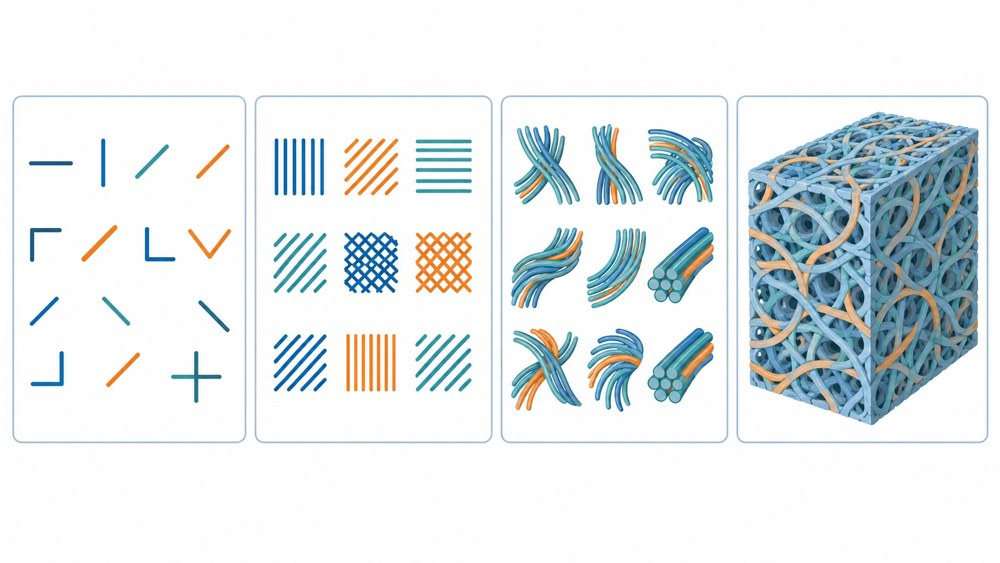

*Deeper layers respond to larger patterns: edges, textures, fibre-like structures, a whole material structure.*

In [ ]:
convs = [l for l in encoder.layers if isinstance(l, layers.Conv2D)]
if not convs:
    raise RuntimeError('The encoder has no convolution layer: run the cells of the CNN autoencoder above first.')
first_conv = convs[0]
W = first_conv.get_weights()[0]                      # shape (3, 3, input channels, number of kernels)
feature_model = models.Model(encoder.inputs, first_conv.output)
fmaps = feature_model.predict(v[-1:], verbose=0)[0]  # shape (nx, ny, number of kernels)

reference = {name: k / np.linalg.norm(k) for name, k in known.items()}
order = np.argsort(-np.linalg.norm(W[:, :, 0, :], axis=(0, 1)))[:8]

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(4, 4, width_ratios=[1, 5, 1, 5])
for j, m in enumerate(order):
    row, col = j % 4, 2 * (j // 4)
    k = W[:, :, 0, m]
    sims = {name: float(np.sum(k * r) / np.linalg.norm(k)) for name, r in reference.items()}
    best = max(sims, key=lambda n: abs(sims[n]))
    label = f'closest: {best} ({sims[best]:+.2f})' if abs(sims[best]) >= 0.5 else 'no close designed kernel'
    lim = np.abs(k).max()
    axk = fig.add_subplot(gs[row, col])
    axk.imshow(np.flipud(k.T), cmap='RdBu_r', vmin=-lim, vmax=lim)
    axk.set_xticks([]); axk.set_yticks([])
    axk.set_title(f'kernel {m}', fontsize=9)
    axf = fig.add_subplot(gs[row, col + 1])
    axf.contourf(xx, yy, fmaps[:, :, m], levels=20, cmap='magma')
    axf.set_aspect('equal'); axf.set_xticks([]); axf.set_yticks([])
    axf.set_title(label, fontsize=10, loc='left')
fig.tight_layout()
plt.show()

Compare with the random kernel above. After training, several kernels resemble smoothing or a derivative in one direction, and others are combinations that nobody would design by hand. Deeper layers combine these feature maps into larger patterns, which is how the encoder reaches a latent vector of length 10.

## Visualization of the modes

We can visualize the spatial modes of the CNN-based autoencoder using the decoder part of the autoencoder. To this end, we consider a latent vector with the first variable equal to one and all other variables equal to zero as the input of the decoder to visualize the first mode. For the second mode, we consider the second variable of the latent vector equal to one and all the others equal to zero. Unlike POD modes, these decoder outputs are not orthogonal, not ranked by energy, and do not add up linearly to the flow field, because the decoder is nonlinear. They show what each latent coordinate does on its own. We perform the same procedure to depict all the spatial modes.

In [ ]:
cm = np.diag(np.ones((d,)))
modes = decoder.predict(cm)

Each row of the plot belongs to one latent coordinate or POD mode: the first two columns show the $u$ and $v$ outputs of the decoder, the last two columns the POD modes 1 to 10 from `U`. Look for pairs of similar POD modes with finer structure as the mode number grows. The AE modes have no such order, as explained above.

In [ ]:
fig, ax = plt.subplots(d, 4, sharex = True, sharey = True, figsize = (10, 16))
i = 0
for axx in ax.flatten()[::4]:
  axx.contourf(xx, yy, modes[i, :, :, 0], levels = 20)
  axx.set_xticks([])
  axx.set_yticks([])
  axx.set_aspect('equal')
  axx.set_title(f'$u$ AE-mode {i + 1}')
  i += 1

i = 0
for axx in ax.flatten()[1::4]:
  axx.contourf(xx, yy, modes[i, :, :, 1], levels = 20)
  axx.set_xticks([])
  axx.set_yticks([])
  axx.set_aspect('equal')
  axx.set_title(f'$v$ AE-mode {i + 1}')
  i += 1

i = 0
for axx in ax.flatten()[2::4]:
  axx.contourf(xx, yy, U[i, :, :, 0], levels = 20)
  axx.set_xticks([])
  axx.set_yticks([])
  axx.set_aspect('equal')
  axx.set_title(f'$u$ POD-mode {i + 1}')
  i += 1

i = 0
for axx in ax.flatten()[3::4]:
  axx.contourf(xx, yy, U[i, :, :, 1], levels = 20)
  axx.set_xticks([])
  axx.set_yticks([])
  axx.set_aspect('equal')
  axx.set_title(f'$v$ POD-mode {i + 1}')
  i += 1

fig.tight_layout()
